In [78]:
from importlib import reload
import TRECCASTeval as trec
import OpenSearchSimpleAPI as osearch
from retrieval_methods.LMD import LMD_Retrieval

import pprint as pp

osearch = reload(osearch)
trec = reload(trec)

lmd = LMD_Retrieval

opensearch = osearch.OSsimpleAPI()
test_bed = trec.ConvSearchEvaluation()
conv_topics = test_bed.train_topics

In [79]:
conv_topic_idx = 0

topic = conv_topics[conv_topic_idx]

turn = topic['turn'][7]
turn_id = turn['number']
utterance = turn['raw_utterance']
print(utterance)


result = lmd.retrieve_fun(opensearch,utterance,200)

What the difference between a PA and a nurse practitioner?
['MARCO_6311185', 'MARCO_7090806', 'MARCO_2849832', 'MARCO_3600884', 'MARCO_7514658', 'MARCO_8579371', 'MARCO_888704', 'MARCO_1908383', 'MARCO_168924', 'MARCO_3144856', 'MARCO_6312729', 'MARCO_4077804', 'MARCO_5407409', 'MARCO_7496118', 'MARCO_3984229', 'MARCO_1908384', 'MARCO_7446928', 'CAR_436ad602db45c2c05a6f1d2b9461f20e8400e60a', 'MARCO_5893872', 'MARCO_5699123', 'MARCO_3951096', 'MARCO_5673918', 'MARCO_6816116', 'MARCO_615449', 'CAR_a1abdc7279a2178f62a20792a69b6bdb95731eea', 'MARCO_1505116', 'MARCO_3984224', 'MARCO_6607048', 'MARCO_6244208', 'MARCO_2904127', 'MARCO_2307794', 'MARCO_4225982', 'MARCO_6311397', 'MARCO_4003509', 'MARCO_364098', 'MARCO_8407876', 'MARCO_4014355', 'MARCO_8716240', 'MARCO_2483667', 'MARCO_5787541', 'MARCO_291620', 'MARCO_7560829', 'MARCO_8503215', 'MARCO_3768527', 'MARCO_2596754', 'MARCO_1827628', 'MARCO_6607056', 'MARCO_6607051', 'MARCO_7342285', 'MARCO_8824030', 'MARCO_3860555', 'MARCO_4518595',

In [80]:
print(result)

                                              _id     _score  \
0                                   MARCO_6311185 -37.655107   
1                                   MARCO_7090806 -39.050118   
2                                   MARCO_2849832 -39.341187   
3                                   MARCO_7514658 -39.952613   
4                                   MARCO_3600884 -43.978987   
..                                            ...        ...   
195                                 MARCO_4847842 -69.825960   
196                                   MARCO_62926 -69.973198   
197                                 MARCO_5604435 -70.994448   
198  CAR_4d4e149f7b51d26af25203d7b69b6dae853f05b9 -73.007611   
199  CAR_eac4c13d758d330e97e60846c09b7df81eb1a404 -73.628529   

                                      _source.doc  
0                                   MARCO_6311185  
1                                   MARCO_7090806  
2                                   MARCO_2849832  
3                      

In [81]:
top_doc = result.iloc[1]
top_doc_body = opensearch.get_doc_body(top_doc._id)
print("TOP DOCUMENT:")
print("-" + top_doc_body)

bottom_doc = result.iloc[170]
bottom_doc_body = opensearch.get_doc_body(bottom_doc._id)
print("BOTTOM DOCUMENT:")
print("-" + bottom_doc_body)


TOP DOCUMENT:
-The Difference Between a Nurse Practitioner (NP) and a Physician Assistant (PA) As many patients know, people rarely see a medical doctor for routine physical examinations anymore. They are far more likely to have an appointment with a Nurse Practitioner (NP) or Physician Assistant (PA) who works in the practice.
BOTTOM DOCUMENT:
-Sand tiger shark. Not to be confused with sand shark, tiger shark, or nurse shark. The sand tiger shark (Carcharias taurus), grey nurse shark, spotted ragged-tooth shark, or blue-nurse sand tiger is a species of shark that inhabits subtropical and temperate waters worldwide.


In [82]:
from sentence_transformers import SentenceTransformer


# Load Dual-Encoder
dual_encoder_path = "sentence-transformers/multi-qa-MiniLM-L6-cos-v1"
dual_encoder = SentenceTransformer(dual_encoder_path)

In [83]:
from transformers import AutoTokenizer, AutoModel, AutoConfig

dual_encoder_tokenizer = AutoTokenizer.from_pretrained(dual_encoder_path)
dual_encoder_config = AutoConfig.from_pretrained(dual_encoder_path, output_hidden_states=True, output_attentions=True)
dual_encoder_model = AutoModel.from_pretrained(dual_encoder_path, config=dual_encoder_config)

In [44]:
# Tokenize the query
query_tokenized = dual_encoder_tokenizer(utterance, return_tensors='pt', max_length=512, padding=True, truncation=True)

# Tokenize the top document (relevant document for positive pair)
top_doc_tokenized = dual_encoder_tokenizer(top_doc_body, return_tensors='pt', max_length=512, padding=True, truncation=True)

# Tokenize the bottom document (non-relevant document for negative pair)
bottom_doc_tokenized = dual_encoder_tokenizer(bottom_doc_body, return_tensors='pt', max_length=512, padding=True, truncation=True)

In [45]:
from torch.nn.functional import cosine_similarity
import torch

# Extract embeddings using the dual encoder model
with torch.no_grad():
    query_embedding = dual_encoder_model(**query_tokenized).last_hidden_state.mean(dim=1)  # Mean pooling
    top_doc_embedding = dual_encoder_model(**top_doc_tokenized).last_hidden_state.mean(dim=1)
    bottom_doc_embedding = dual_encoder_model(**bottom_doc_tokenized).last_hidden_state.mean(dim=1)

In [20]:
from torch.nn.functional import cosine_similarity

# Compute cosine similarity for positive and negative pairs
dual_encoder_POS = cosine_similarity(query_embedding, top_doc_embedding)
dual_encoder_NEG = cosine_similarity(query_embedding, bottom_doc_embedding)


tensor([0.7994])


In [27]:
# Tokenize query
query_tokens = dual_encoder_tokenizer(utterance, return_tensors='pt')

# Decode the query input IDs
print("Decoded Query:")
print(dual_encoder_tokenizer.decode(query_tokens["input_ids"][0]))

# Convert input IDs to token list for the query
query_input_ids = query_tokens["input_ids"][0].tolist()
query_tokens_list = dual_encoder_tokenizer.convert_ids_to_tokens(query_input_ids)
print("Query Tokens:")
print(query_tokens_list)

Decoded Query:
[CLS] what the difference between a pa and a nurse practitioner? [SEP]
Query Tokens:
['[CLS]', 'what', 'the', 'difference', 'between', 'a', 'pa', 'and', 'a', 'nurse', 'practitioner', '?', '[SEP]']


In [28]:
# Tokenize relevant document (positive pair)
pos_doc_tokens = dual_encoder_tokenizer(top_doc_body, return_tensors='pt')

# Decode the document input IDs
print("Decoded Positive Document:")
print(dual_encoder_tokenizer.decode(pos_doc_tokens["input_ids"][0]))

# Convert input IDs to token list for the document
pos_doc_input_ids = pos_doc_tokens["input_ids"][0].tolist()
pos_doc_tokens_list = dual_encoder_tokenizer.convert_ids_to_tokens(pos_doc_input_ids)
print("Positive Document Tokens:")
print(pos_doc_tokens_list)

Decoded Positive Document:
[CLS] the difference between a nurse practitioner ( np ) and a physician assistant ( pa ) as many patients know, people rarely see a medical doctor for routine physical examinations anymore. they are far more likely to have an appointment with a nurse practitioner ( np ) or physician assistant ( pa ) who works in the practice. [SEP]
Positive Document Tokens:
['[CLS]', 'the', 'difference', 'between', 'a', 'nurse', 'practitioner', '(', 'np', ')', 'and', 'a', 'physician', 'assistant', '(', 'pa', ')', 'as', 'many', 'patients', 'know', ',', 'people', 'rarely', 'see', 'a', 'medical', 'doctor', 'for', 'routine', 'physical', 'examinations', 'anymore', '.', 'they', 'are', 'far', 'more', 'likely', 'to', 'have', 'an', 'appointment', 'with', 'a', 'nurse', 'practitioner', '(', 'np', ')', 'or', 'physician', 'assistant', '(', 'pa', ')', 'who', 'works', 'in', 'the', 'practice', '.', '[SEP]']


## FOR POSITIVE


In [84]:
#ACHO QUE SO FAZ SENTIDO A PARTIR DAQUI
#(os acima são desnecessários) acho que é possivel juntar tudo

dual_encoder_POS = dual_encoder_tokenizer(utterance, top_doc_body, return_tensors='pt', max_length=512, truncation=True, padding=True)

# Decode combined tokens


print("Decoded Positive Pair:")
print(dual_encoder_tokenizer.decode(dual_encoder_POS["input_ids"][0]))


# Convert input IDs to token list for the query

input_ids_POS = dual_encoder_POS['input_ids']
input_ids_POS_list = input_ids_POS[0].tolist()
input_tokens_POS_list = dual_encoder_tokenizer.convert_ids_to_tokens(input_ids_POS_list)
print("Query Tokens:")
print(input_tokens_POS_list) 

Decoded Positive Pair:
[CLS] what the difference between a pa and a nurse practitioner? [SEP] the difference between a nurse practitioner ( np ) and a physician assistant ( pa ) as many patients know, people rarely see a medical doctor for routine physical examinations anymore. they are far more likely to have an appointment with a nurse practitioner ( np ) or physician assistant ( pa ) who works in the practice. [SEP]
Query Tokens:
['[CLS]', 'what', 'the', 'difference', 'between', 'a', 'pa', 'and', 'a', 'nurse', 'practitioner', '?', '[SEP]', 'the', 'difference', 'between', 'a', 'nurse', 'practitioner', '(', 'np', ')', 'and', 'a', 'physician', 'assistant', '(', 'pa', ')', 'as', 'many', 'patients', 'know', ',', 'people', 'rarely', 'see', 'a', 'medical', 'doctor', 'for', 'routine', 'physical', 'examinations', 'anymore', '.', 'they', 'are', 'far', 'more', 'likely', 'to', 'have', 'an', 'appointment', 'with', 'a', 'nurse', 'practitioner', '(', 'np', ')', 'or', 'physician', 'assistant', '(',

In [85]:
res_POS = "\n".join("{} \t {}".format(x, y) for x, y in zip(input_ids_POS_list, input_tokens_POS_list))
print(res_POS)



101 	 [CLS]
2054 	 what
1996 	 the
4489 	 difference
2090 	 between
1037 	 a
6643 	 pa
1998 	 and
1037 	 a
6821 	 nurse
18742 	 practitioner
1029 	 ?
102 	 [SEP]
1996 	 the
4489 	 difference
2090 	 between
1037 	 a
6821 	 nurse
18742 	 practitioner
1006 	 (
27937 	 np
1007 	 )
1998 	 and
1037 	 a
7522 	 physician
3353 	 assistant
1006 	 (
6643 	 pa
1007 	 )
2004 	 as
2116 	 many
5022 	 patients
2113 	 know
1010 	 ,
2111 	 people
6524 	 rarely
2156 	 see
1037 	 a
2966 	 medical
3460 	 doctor
2005 	 for
9410 	 routine
3558 	 physical
14912 	 examinations
4902 	 anymore
1012 	 .
2027 	 they
2024 	 are
2521 	 far
2062 	 more
3497 	 likely
2000 	 to
2031 	 have
2019 	 an
6098 	 appointment
2007 	 with
1037 	 a
6821 	 nurse
18742 	 practitioner
1006 	 (
27937 	 np
1007 	 )
2030 	 or
7522 	 physician
3353 	 assistant
1006 	 (
6643 	 pa
1007 	 )
2040 	 who
2573 	 works
1999 	 in
1996 	 the
3218 	 practice
1012 	 .
102 	 [SEP]


In [86]:
with torch.no_grad():
    outputs = dual_encoder_model(**dual_encoder_POS)

attention = outputs.attentions
hidden_states = outputs.hidden_states


first_layer_embeddings = hidden_states[0][0]  
last_layer_embeddings = hidden_states[-1][0]  


first_10_tokens_first_layer = first_layer_embeddings[:10].detach().numpy()
first_10_tokens_last_layer = last_layer_embeddings[:10].detach().numpy()

In [87]:
import matplotlib.pyplot as plt
plt.style.use('ggplot')

# 
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

def display_scatterplot(data, words):

    if data.shape[1] == 2:
        twodim = data
    else:
        pca = PCA()
        pca.fit(data)
        twodim = pca.transform(data)[:,:2]
    
    plt.style.use('default') # https://matplotlib.org/3.5.1/gallery/style_sheets/style_sheets_reference.html
    plt.figure(figsize=(6,6))
    plt.scatter(twodim[:,0], twodim[:,1], edgecolors='k', c='r')
    for word, (x,y) in zip(words, twodim):
        plt.text(x+0.05, y+0.05, word)

    return

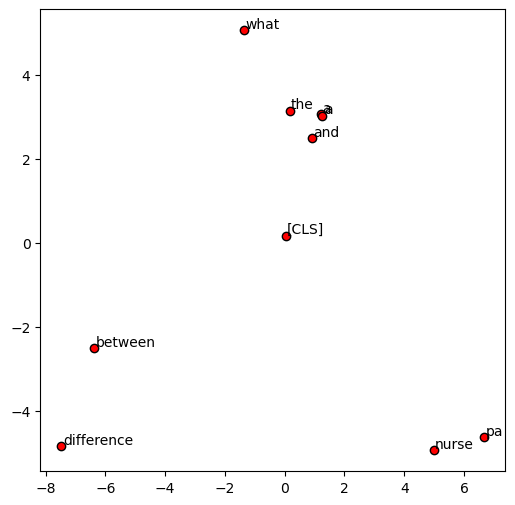

In [88]:
#Plot the token embeddings of the first-layer  
display_scatterplot(first_10_tokens_first_layer, input_tokens_POS_list[:10])

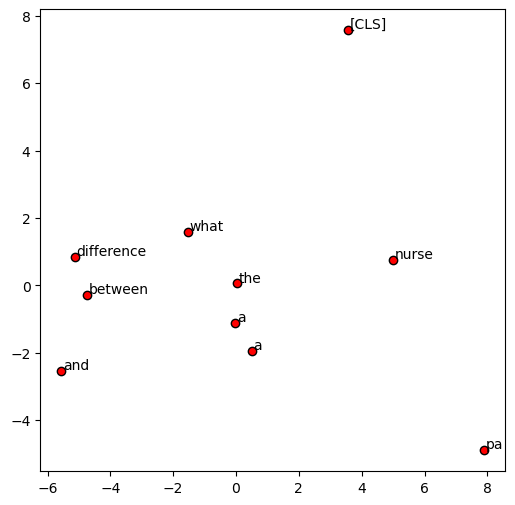

In [89]:
#Plot the token embeddings of the last-layer 
display_scatterplot(first_10_tokens_last_layer, input_tokens_POS_list[:10])

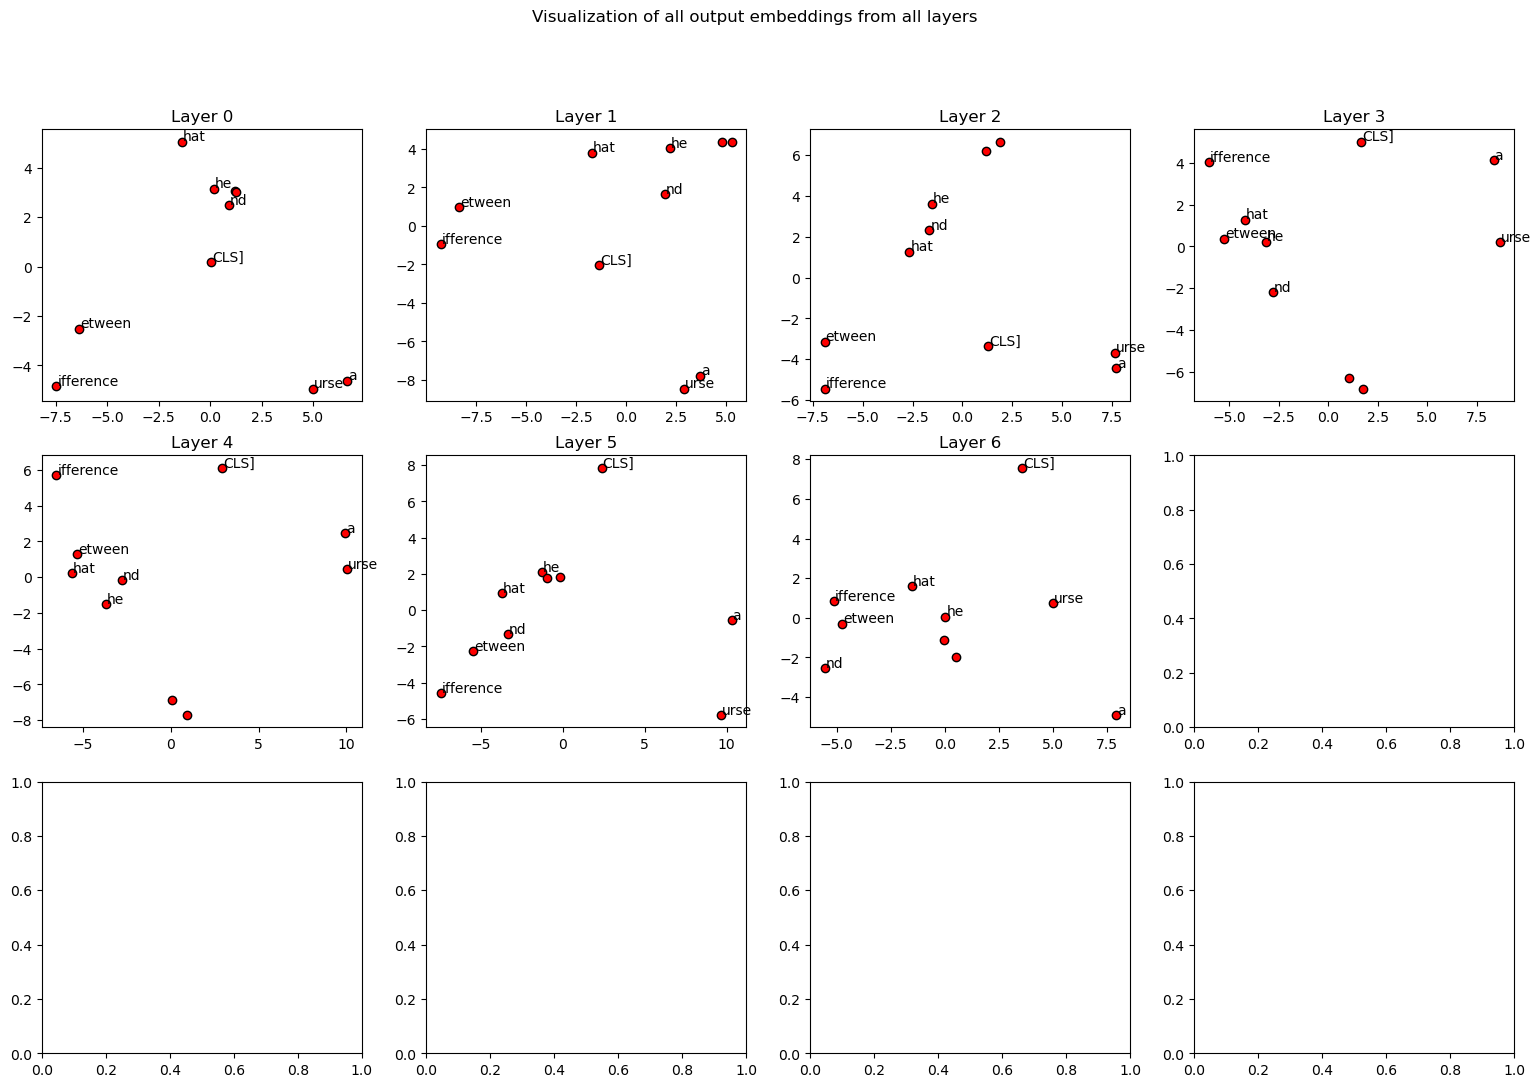

In [92]:
#REPEAT FOR ALL

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

layer = 1

rows = 3
cols = 4
fig, ax_full = plt.subplots(rows, cols)
fig.set_figheight(rows*4)
fig.set_figwidth(cols*4+3)
plt.rcParams.update({'font.size': 6})


layer = 0
for r in range(rows):
    for c in range(cols):
        if layer >= len(hidden_states): 
            break
       
        ax = ax_full[r,c]
        
        plt.rcParams.update({'font.size': 10})
        current_hidden_state = hidden_states[layer][0].detach().numpy()

        current_hidden_state = current_hidden_state[:10]
        
        if current_hidden_state.shape[1] == 2:
            twodim = current_hidden_state
        else:
            twodim = PCA().fit_transform(current_hidden_state)[:,:2]

        plt.style.use('default') # https://matplotlib.org/3.5.1/gallery/style_sheets/style_sheets_reference.html
        im = ax.scatter(twodim[:,0], twodim[:,1], edgecolors='k', c='r')
        for word, (x,y) in zip(input_tokens_POS_list, twodim):
            ax.text(x+0.05, y+0.05, word[1:])
        
        # Show all ticks and label them with the respective list entries
        ax.set_title("Layer " + str(layer))
            
        # Loop over data dimensions and create text annotations.
        layer = layer + 1

fig.suptitle("Visualization of all output embeddings from all layers")
plt.show()


In [93]:
#SIMILARITY

with torch.no_grad():
    outputs = dual_encoder_model(**dual_encoder_POS)

attention = outputs.attentions
hidden_states = outputs.hidden_states


first_layer_embeddings = hidden_states[0][0]  # Shape: (num_tokens, hidden_dim)
last_layer_embeddings = hidden_states[-1][0]  # Shape: (num_tokens, hidden_dim)


first_10_tokens_first_layer = first_layer_embeddings[:10].detach().numpy()
first_10_tokens_last_layer = last_layer_embeddings[:10].detach().numpy()

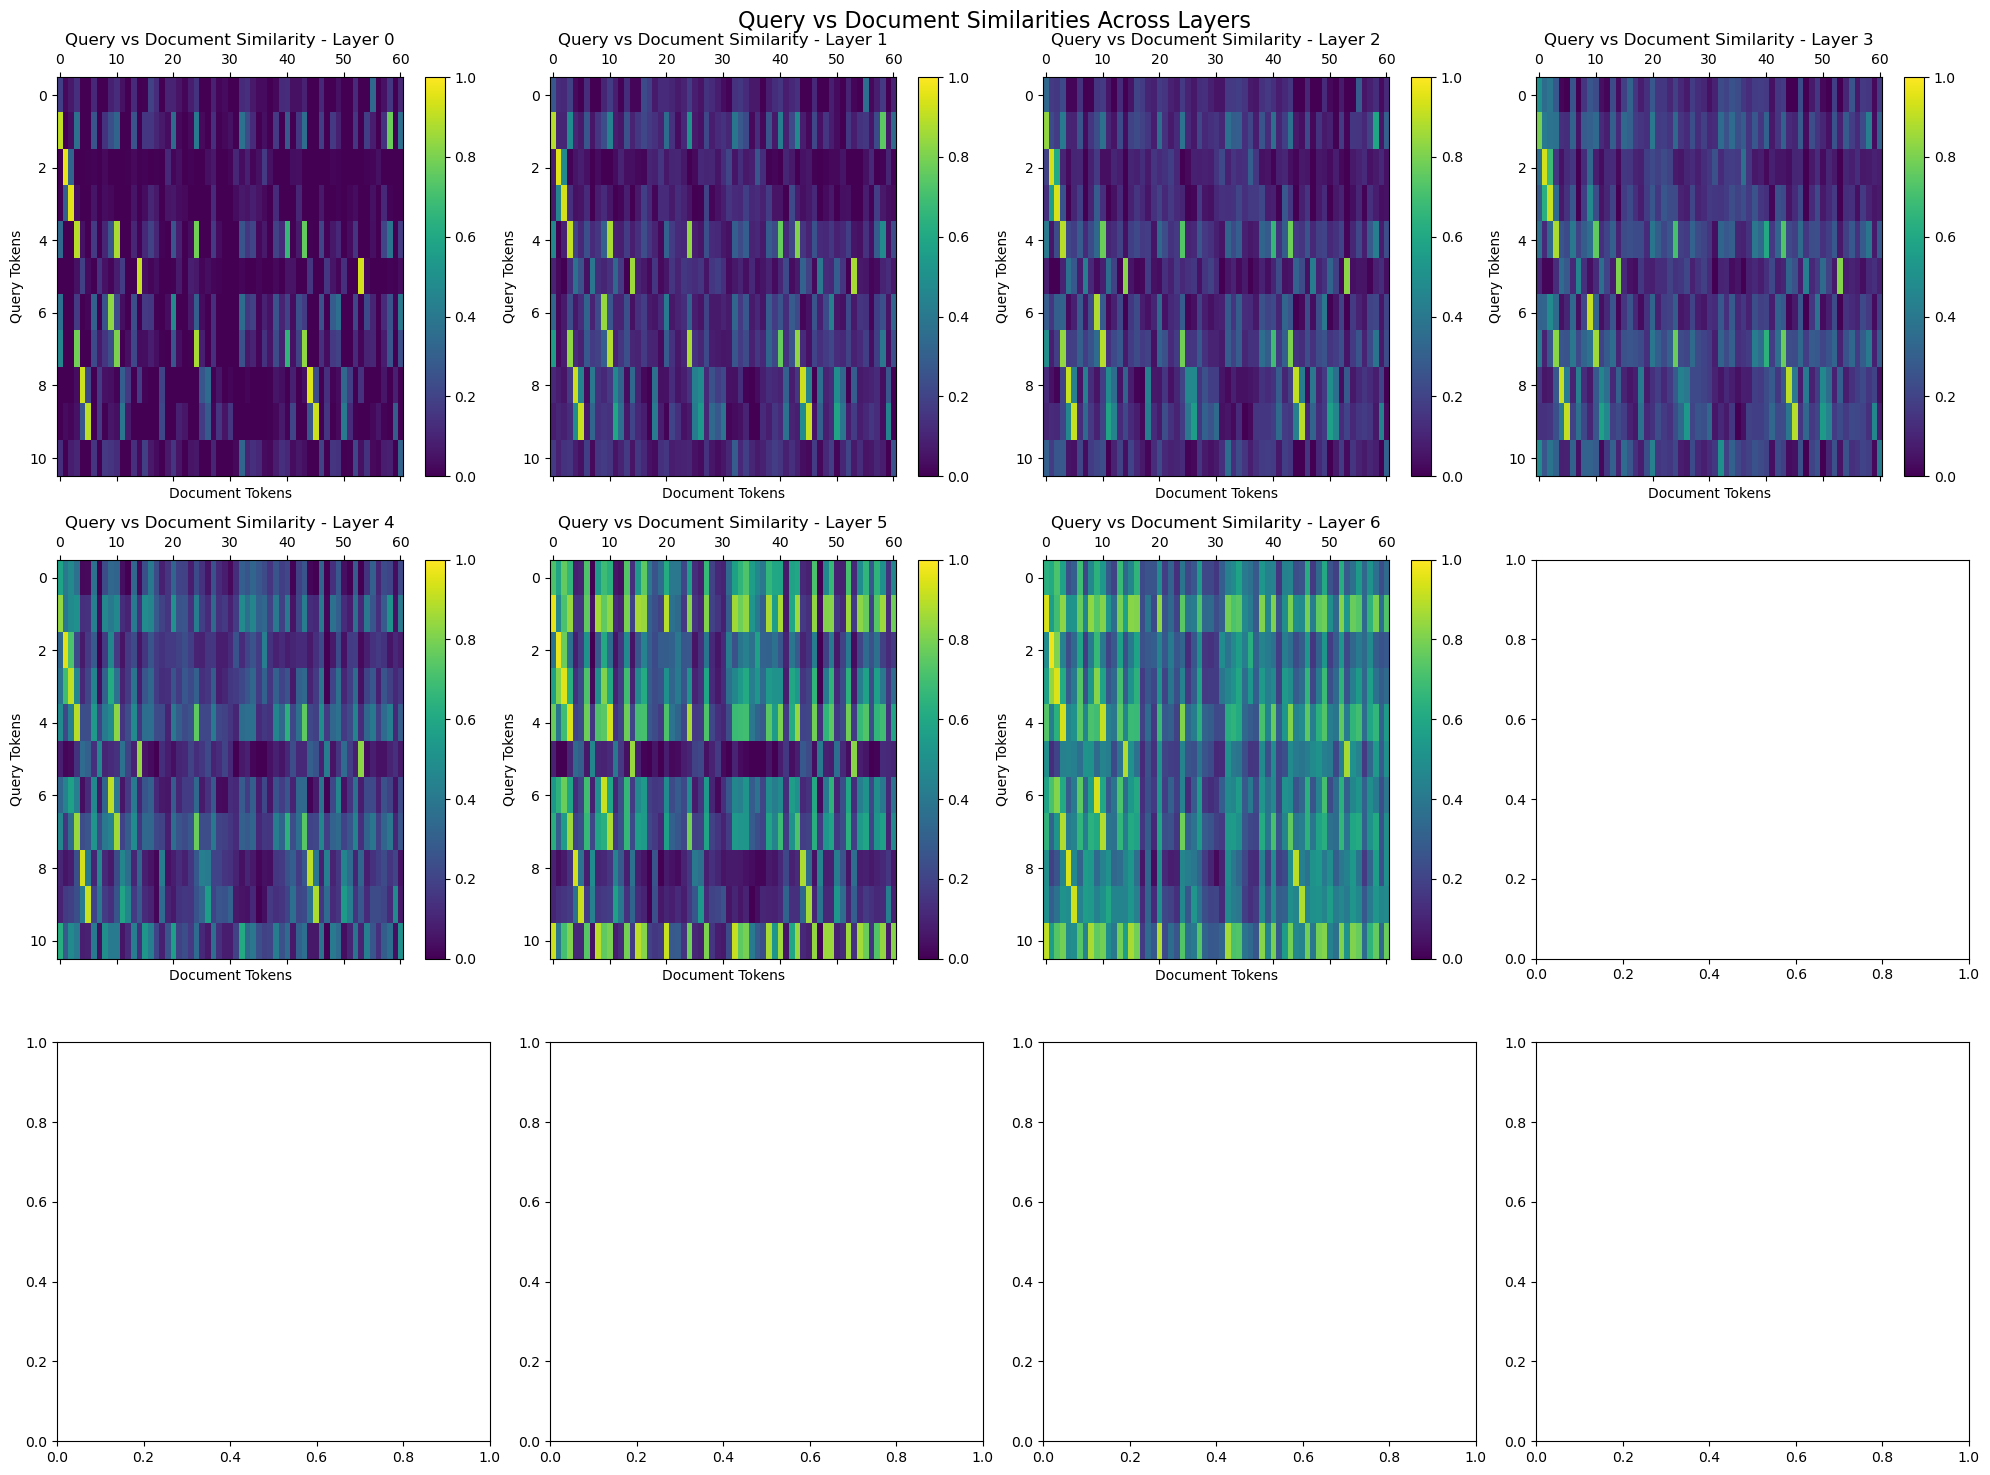

In [94]:
# Determine indices of query and document tokens
sep_token_id = dual_encoder_tokenizer.sep_token_id  # Get the ID of [SEP]
input_ids_POS_list = input_ids_POS[0].tolist()    

query_indices = range(1, input_ids_POS_list.index(sep_token_id))  

# Document tokens are between the first [SEP] and the second [SEP]
doc_indices = range(input_ids_POS_list.index(sep_token_id) + 1, len(input_ids_POS_list) - 1)

from sklearn.metrics.pairwise import cosine_similarity


similarities = []

for layer in range(len(hidden_states)):
    layer_embeddings = hidden_states[layer][0].detach().numpy()
    query_embeddings = layer_embeddings[query_indices]
    doc_embeddings = layer_embeddings[doc_indices]

    # Compute similarity matrix
    similarity_matrix = cosine_similarity(query_embeddings, doc_embeddings)
    similarities.append(similarity_matrix)


import matplotlib.pyplot as plt
import numpy as np

# Assuming similarities is a list of similarity matrices (one for each layer)
rows, cols = 3, 4  # Adjust based on the number of layers
fig, ax_full = plt.subplots(rows, cols, figsize=(20, 15))

layer = 0
for r in range(rows):
    for c in range(cols):
        if layer >= len(similarities):  # Avoid indexing beyond available layers
            break
        
        ax = ax_full[r, c]
        similarity_matrix = similarities[layer]
        
        # Plot similarity matrix using matshow (alternative to heatmap)
        cax = ax.matshow(similarity_matrix, cmap="viridis", aspect='auto', vmin=0, vmax=1)

        ax.set_title(f"Query vs Document Similarity - Layer {layer}")
        ax.set_xlabel("Document Tokens")
        ax.set_ylabel("Query Tokens")
        
        # Add colorbar to the side
        fig.colorbar(cax, ax=ax)

        layer += 1

plt.suptitle("Query vs Document Similarities Across Layers", fontsize=16)
plt.tight_layout()
plt.show()

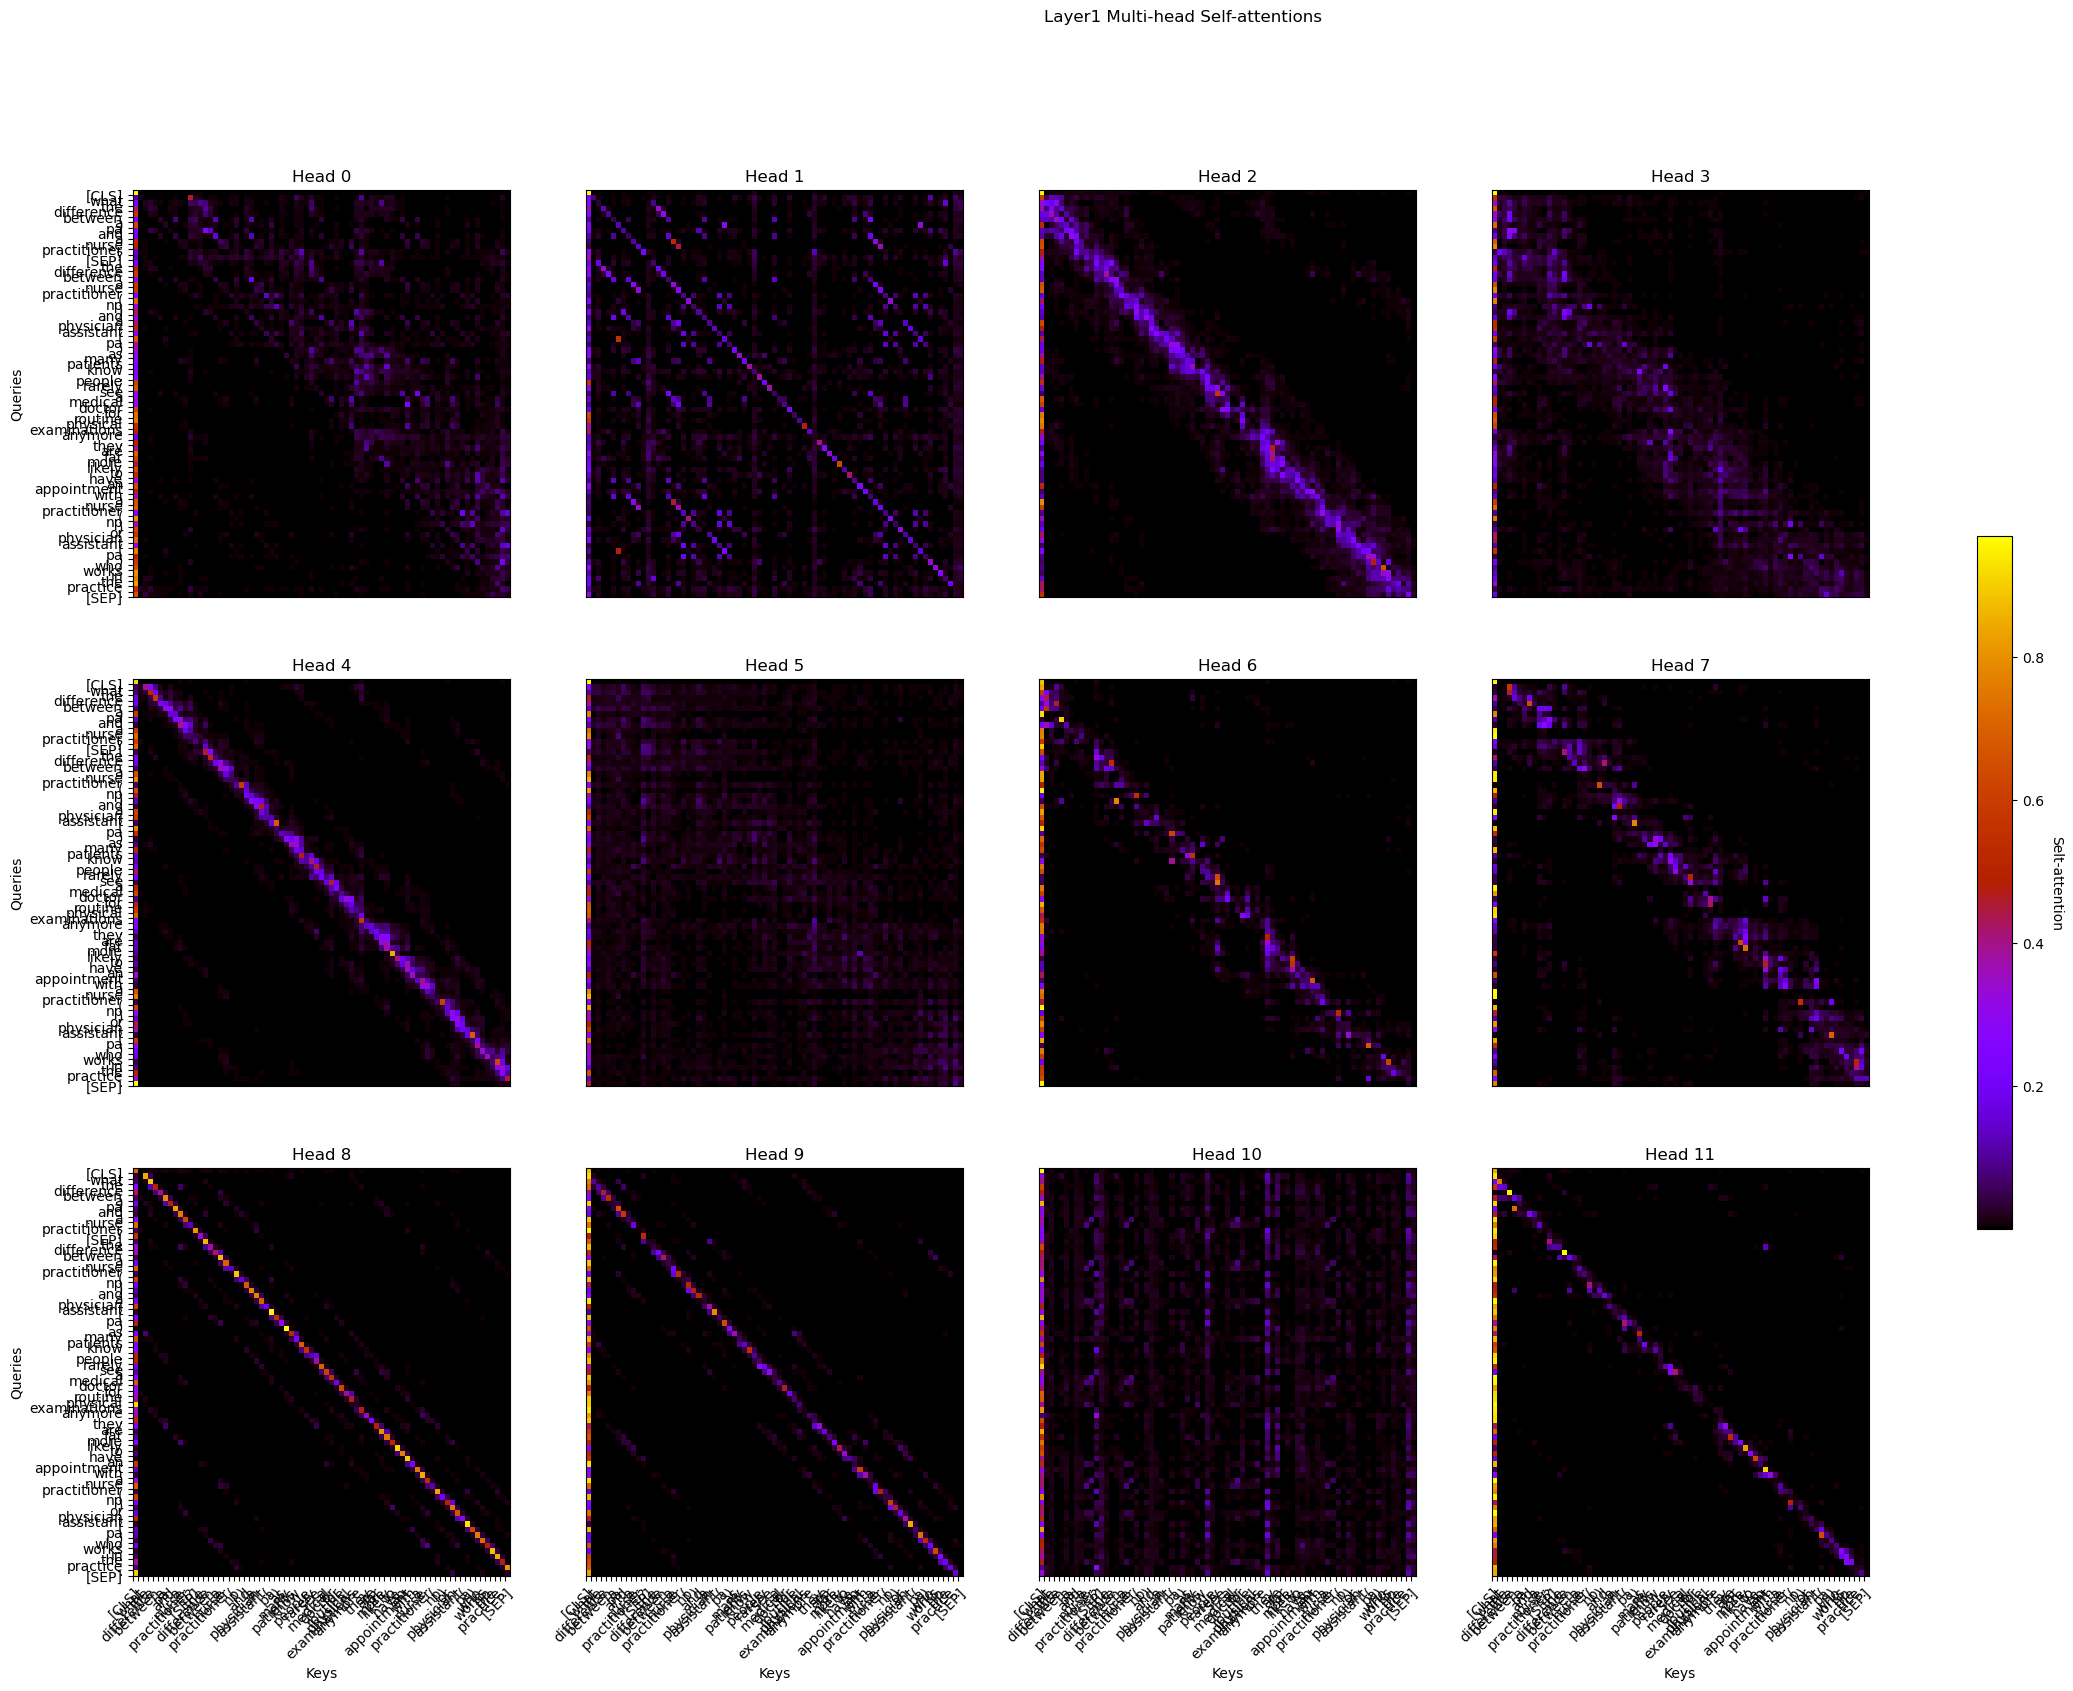

In [95]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

layer = 1

rows = 3
cols = 4
fig, ax_full = plt.subplots(rows, cols)
fig.set_figheight(rows*6)
fig.set_figwidth(cols*6+4)
plt.rcParams.update({'font.size': 10})


j = 0
for r in range(rows):
    for c in range(cols):
        
        ax = ax_full[r,c]
        
        sattention = attention[layer][0][j].numpy()
        sattention = np.flip(sattention, 0)
        
        plt.rcParams.update({'font.size': 10})

        im = ax.pcolormesh(sattention, cmap='gnuplot')

        # Show all ticks and label them with the respective list entries
        ax.set_title("Head " + str(j))
        ax.set_yticks(np.arange(len(input_tokens_POS_list)))
        if c == 0:
            ax.set_yticklabels(reversed(input_tokens_POS_list))
            ax.set_ylabel("Queries")
        else:
            ax.set_yticks([])

        ax.set_xticks(np.arange(len(input_tokens_POS_list)))
        if r == rows-1:
            ax.set_xticklabels(input_tokens_POS_list)
            ax.set_xlabel("Keys")
            
            # Rotate the tick labels and set their alignment.
            plt.setp(ax.get_xticklabels(), rotation=45, ha="right",
                     rotation_mode="anchor")
        else:
            ax.set_xticks([])

            
        # Loop over data dimensions and create text annotations.
        j = j + 1

fig.suptitle("Layer" + str(layer) + " Multi-head Self-attentions")
cbar = fig.colorbar(im, ax=ax_full, location='right', shrink=0.5)
cbar.ax.set_ylabel("Selt-attention", rotation=-90, va="bottom")

#plt.figure(figsize=(x,y))

plt.show()


## FOR NEGATIVE



In [ ]:


dual_encoder_NEG = dual_encoder_tokenizer(utterance, top_doc_body, return_tensors='pt', max_length=512, truncation=True, padding=True)

# Decode combined tokens


print("Decoded Positive Pair:")
print(dual_encoder_tokenizer.decode(dual_encoder_POS["input_ids"][0]))


# Convert input IDs to token list for the query

input_ids_POS = dual_encoder_POS['input_ids']
input_ids_POS_list = input_ids_POS[0].tolist()
input_tokens_POS_list = dual_encoder_tokenizer.convert_ids_to_tokens(input_ids_POS_list)
print("Query Tokens:")
print(input_tokens_POS_list) 